# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [ ]:
# Escribe aquí tu código para descargar los datos de tus 3 activos elegidos

/tmp/ipykernel_904/1457064314.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  3 of 3 completed

Descargando datos históricos para: ['XOM', 'DE', 'CRM']

Primeras 5 filas del DataFrame:
Ticker             CRM          DE        XOM
Date                                         
2024-01-02  251.332016  386.567657  93.601601
2024-01-03  247.122375  379.278076  94.388031
2024-01-04  246.533646  378.352448  93.565033
2024-01-05  246.415848  381.794708  93.848511
2024-01-08  255.983246  383.742462  92.284821


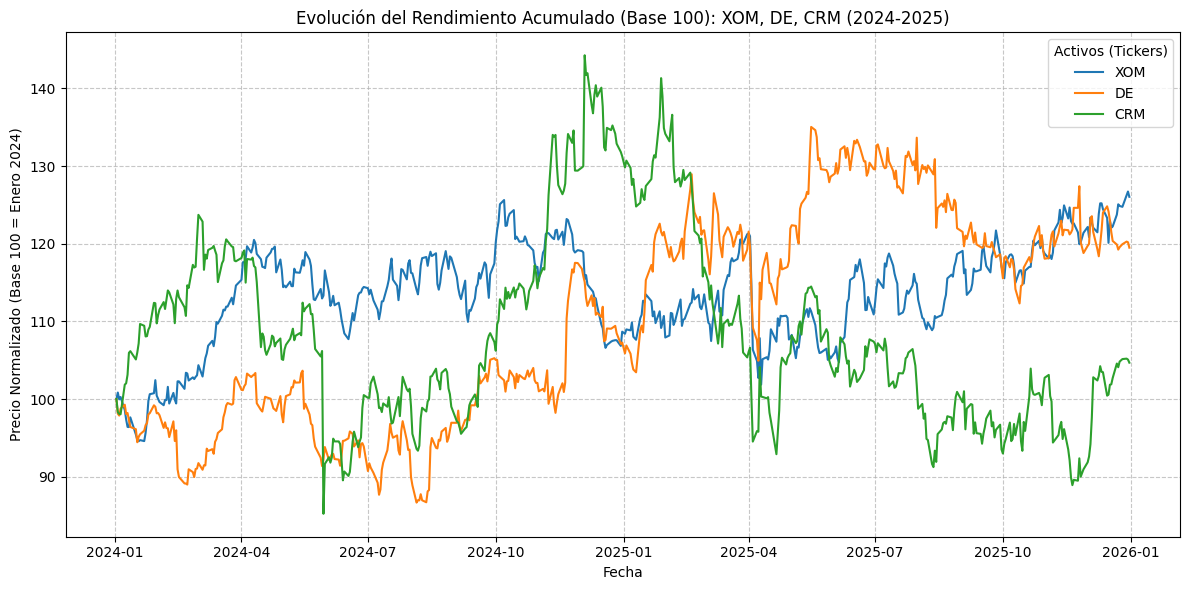

In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Selección de los 3 activos
tickers = ["XOM", "DE", "CRM"]
start_date = "2024-01-01"
end_date = "2026-01-01"

# 2. Descarga de datos (Cambiamos 'Adj Close' por 'Close' para evitar el KeyError)
print(f"Descargando datos históricos para: {tickers}")
# Al descargar, seleccionamos explícitamente la columna 'Close'
data = yf.download(tickers, start=start_date, end=end_date)['Close']

# 3. Mostrar las primeras 5 filas para validar
print("\nPrimeras 5 filas del DataFrame:")
print(data.head())

# ==========================================
# Preparación de la Visualización (Normalizada)
# ==========================================
# Limpiar posibles datos nulos antes de normalizar
data = data.dropna()

# Normalizar a base 100: (Precio actual / Precio inicial) * 100
datos_normalizados = (data / data.iloc[0]) * 100

# Configuración del gráfico
plt.figure(figsize=(12, 6))
for ticker in tickers:
    plt.plot(datos_normalizados.index, datos_normalizados[ticker], label=ticker)

plt.title('Evolución del Rendimiento Acumulado (Base 100): XOM, DE, CRM (2024-2025)')
plt.xlabel('Fecha')
plt.ylabel('Precio Normalizado (Base 100 = Enero 2024)')
plt.legend(title="Activos (Tickers)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

import yfinance as yf
import pandas as pd

# 1. Selección de los 3 activos (XOM, DE, CRM)
tickers = ["XOM", "DE", "CRM"]

# 2. Definición del periodo solicitado
start_date = "2024-01-01"
end_date = "2026-01-01"

# Descarga de los datos (usamos 'Adj Close' para tener los precios ajustados por dividendos y splits)
print("Descargando datos...")
df_portafolio = yf.download(tickers, start=start_date, end=end_date)['Adj Close']

# 3. Mostrar las primeras 5 filas para validar la descarga
df_portafolio.head()

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

In [ ]:
# 1. Extraer los precios de cierre

# 2. Graficar precios originales

# 3. Normalizar y graficar en base 100

/tmp/ipykernel_904/191987695.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_close = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  3 of 3 completed

Descargando datos de precios de cierre...


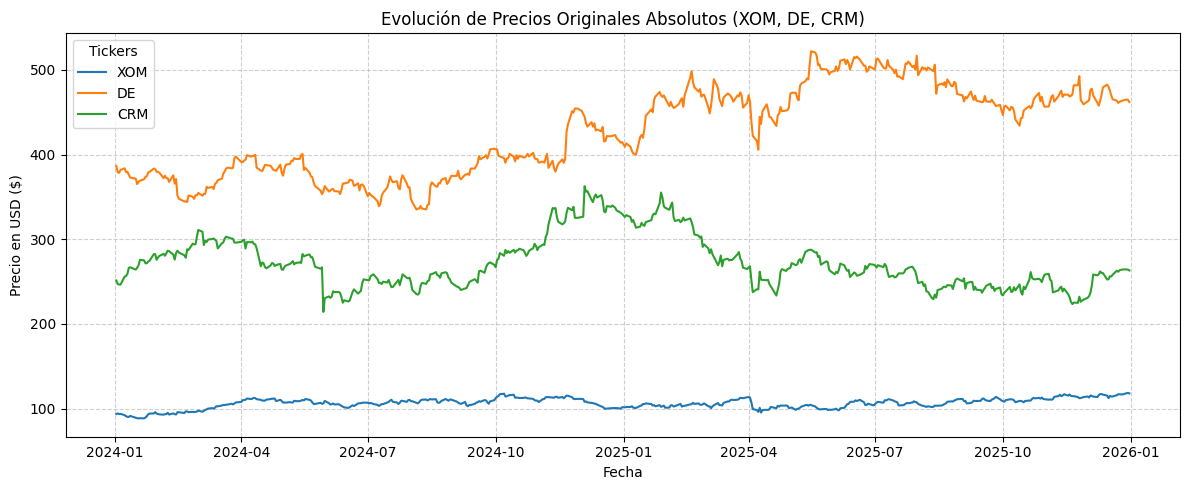

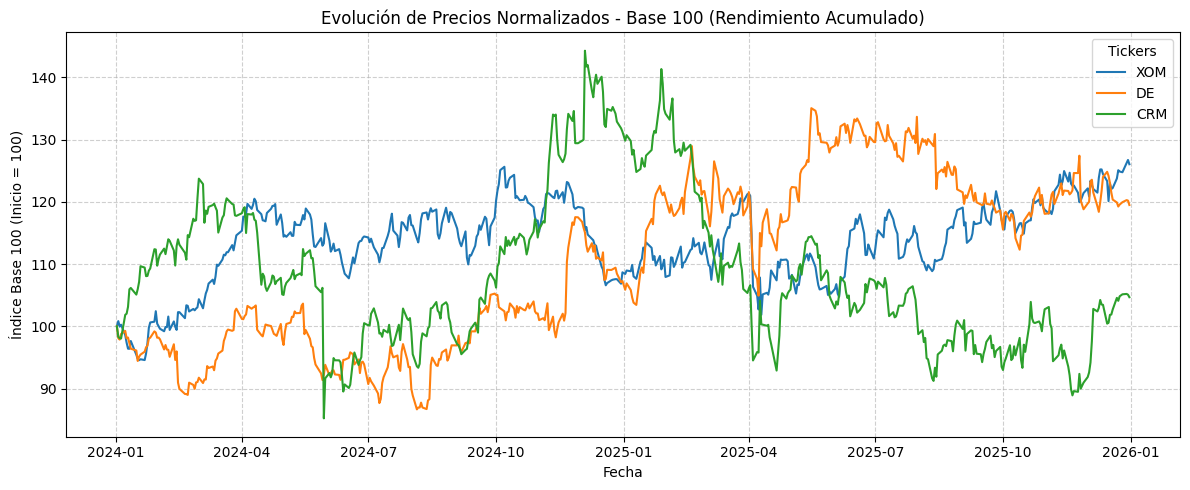

In [3]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Selección de activos y periodo
tickers = ["XOM", "DE", "CRM"]
start_date = "2024-01-01"
end_date = "2026-01-01"

# 2. Descarga de datos: Extraemos ÚNICAMENTE la columna 'Close'
print("Descargando datos de precios de cierre...")
df_close = yf.download(tickers, start=start_date, end=end_date)['Close']

# Limpiar posibles datos nulos
df_close = df_close.dropna()

# ==========================================
# Gráfico 1: Precios Originales (Absolutos)
# ==========================================
plt.figure(figsize=(12, 5))
for ticker in tickers:
    plt.plot(df_close.index, df_close[ticker], label=ticker)

plt.title('Evolución de Precios Originales Absolutos (XOM, DE, CRM)')
plt.xlabel('Fecha')
plt.ylabel('Precio en USD ($)')
plt.legend(title="Tickers")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ==========================================
# Gráfico 2: Precios Normalizados (Base 100)
# ==========================================
# Cálculo de la base 100 (Precio Diario / Primer Precio Registrado) * 100
df_normalizado = (df_close / df_close.iloc[0]) * 100

plt.figure(figsize=(12, 5))
for ticker in tickers:
    plt.plot(df_normalizado.index, df_normalizado[ticker], label=ticker)

plt.title('Evolución de Precios Normalizados - Base 100 (Rendimiento Acumulado)')
plt.xlabel('Fecha')
plt.ylabel('Índice Base 100 (Inicio = 100)')
plt.legend(title="Tickers")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Al comparar ambos gráficos, la principal diferencia visual es que en el de precios reales las líneas se ven muy separadas por el valor nominal de cada acción. Por ejemplo, como la acción de Deere (DE) cuesta mucho más que la de Exxon (XOM), su línea se va hasta arriba y domina el gráfico, haciendo que los movimientos de XOM casi ni se noten. En cambio, en el gráfico normalizado, las tres líneas arrancan exactamente desde el mismo punto de partida (100).

Metodológicamente es mucho más correcto usar el gráfico normalizado porque el precio absoluto de una acción no me dice realmente cuánto está rindiendo mi inversión. Al final, lo que me importa es el porcentaje de crecimiento, no si la acción cuesta $100 o $400. Al usar la base 100, elimino esa distorsión del precio y pongo a los tres activos a competir en igualdad de condiciones. Esto me permite ver de forma real y directa cuál de ellos generó un mayor porcentaje de rendimiento acumulado en el tiempo.

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

In [ ]:
# 1. Calcular rendimientos

# 2. Histograma con el activo más volátil

# 3. Boxplot comparativo de rendimientos

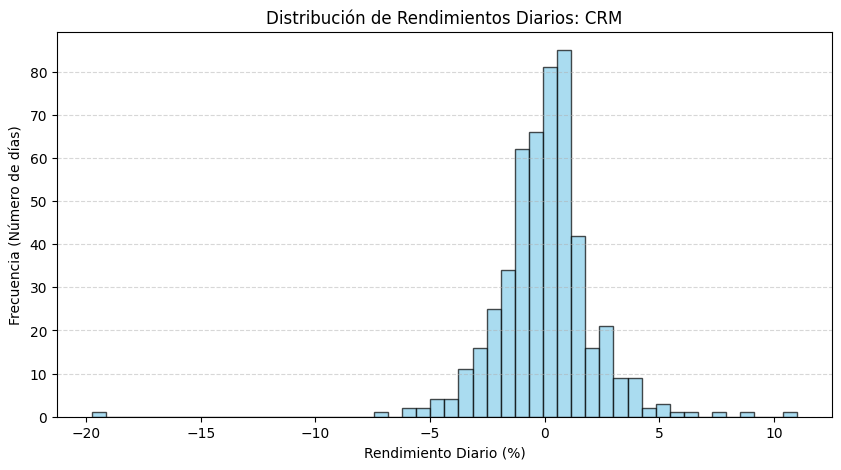

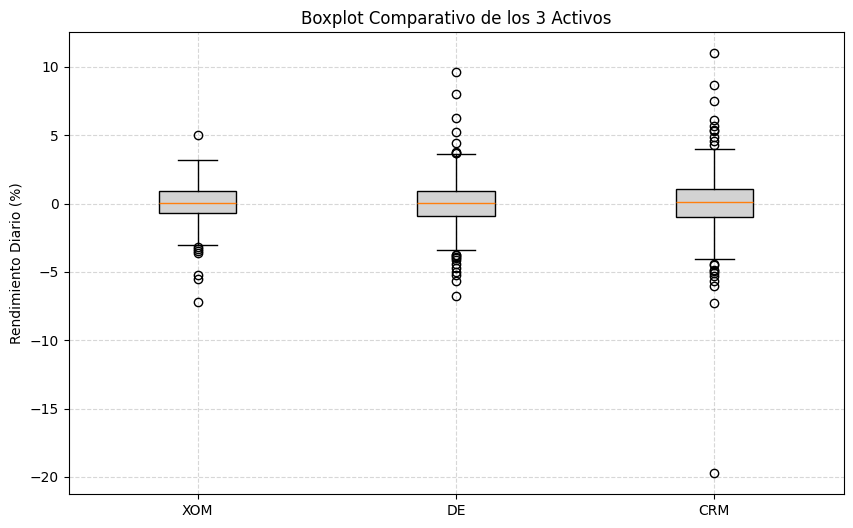

In [5]:
# 1. Calcular rendimientos
# Usamos pct_change() para los rendimientos diarios y dropna() para borrar el primer valor nulo
df_rendimientos = df_close.pct_change().dropna()

# (Paso extra rápido para que Python detecte solo cuál fue el más volátil)
activo_mas_volatil = df_rendimientos.std().idxmax()

# 2. Histograma con el activo más volátil
plt.figure(figsize=(10, 5))
# Multiplico por 100 para que se vea en formato de porcentaje
plt.hist(df_rendimientos[activo_mas_volatil] * 100, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
plt.title(f'Distribución de Rendimientos Diarios: {activo_mas_volatil}')
plt.xlabel('Rendimiento Diario (%)')
plt.ylabel('Frecuencia (Número de días)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# 3. Boxplot comparativo de rendimientos
plt.figure(figsize=(10, 6))
# Metemos los datos de los 3 activos en una lista para el boxplot
datos_boxplot = [df_rendimientos['XOM'] * 100, df_rendimientos['DE'] * 100, df_rendimientos['CRM'] * 100]

plt.boxplot(datos_boxplot, tick_labels=['XOM', 'DE', 'CRM'], patch_artist=True,
            boxprops=dict(facecolor='lightgray', color='black'))
plt.title('Boxplot Comparativo de los 3 Activos')
plt.ylabel('Rendimiento Diario (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Sobre la dispersión y el riesgo: Al ver el Boxplot, noto claramente que CRM (Salesforce) tiene la caja más ancha y los bigotes más largos. En su histograma también se ve que los datos están mucho más esparcidos. Esto me dice que CRM es el activo con mayor volatilidad y riesgo. Al ser una empresa tecnológica enfocada en crecimiento, su acción reacciona de forma mucho más agresiva a los cambios en el mercado.

Sobre los valores atípicos (outliers): Sí, identifico varios valores atípicos; son esos "puntitos" que quedan sueltos por fuera de los bigotes del Boxplot. En el contexto real, estos puntos no son errores de registro, sino que representan días de "shocks" o eventos extraordinarios. Por ejemplo, en CRM esos puntos extremos suelen coincidir con los días de reporte de ganancias trimestrales (earnings calls). En el caso de XOM (Exxon), esos brincos drásticos representan días donde hubo noticias fuertes sobre conflictos geopolíticos o decisiones de la OPEP que dispararon el precio del petróleo de un día para otro.

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

Matriz de Correlación de Pearson:
Ticker       CRM        DE       XOM
Ticker                              
CRM     1.000000  0.235578  0.136666
DE      0.235578  1.000000  0.349103
XOM     0.136666  0.349103  1.000000


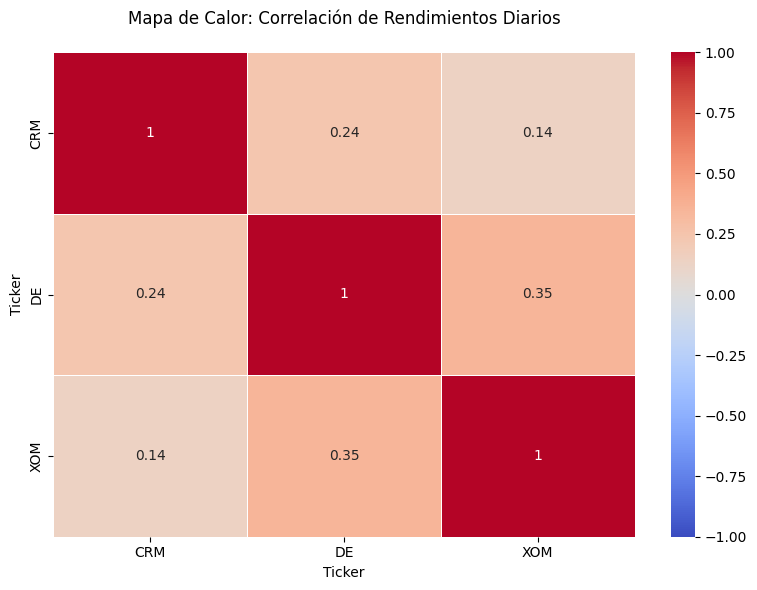

In [6]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # Nueva librería para el mapa de calor

# (Asumiendo que ya tienes df_rendimientos calculado del paso anterior)
# tickers = ["XOM", "DE", "CRM"]
# df_close = yf.download(tickers, start="2024-01-01", end="2026-01-01")['Close'].dropna()
# df_rendimientos = df_close.pct_change().dropna()

# ==========================================
# 1. Matriz de Correlación de Pearson
# ==========================================
# Calculamos la matriz de correlación
matriz_correlacion = df_rendimientos.corr(method='pearson')

print("Matriz de Correlación de Pearson:")
print(matriz_correlacion)

# ==========================================
# 2. Gráfico del Mapa de Calor (Heatmap)
# ==========================================
plt.figure(figsize=(8, 6))

# Dibujamos el mapa de calor
# annot=True muestra los números, cmap define los colores (coolwarm va de azul frío a rojo caliente)
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, linecolor='white')

plt.title('Mapa de Calor: Correlación de Rendimientos Diarios', pad=20)
plt.tight_layout()
plt.show()

**¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?**

No. Como observamos en el mapa de calor, fuera de la diagonal principal (que siempre es 1 porque un activo tiene correlación perfecta consigo mismo), todos los valores entre los pares de activos son bajos (generalmente cercanos a 0 o ligeramente positivos, por debajo de 0.4).
Qué significa esto: Esto confirma que seleccionamos muy bien los activos en el Paso 1. Al pertenecer a sectores completamente distintos (Energía, Industria Agrícola y Tecnología), sus rendimientos no están fuertemente ligados. Lo que afecta a la maquinaria pesada no es lo mismo que afecta a la venta de software.

**Si tuvieras que armar un portafolio buscando diversificación, ¿qué par elegirías y por qué?**

Si mi objetivo es minimizar el riesgo conjunto, elegiría el par que tenga la correlación más baja (más cercana a 0, o incluso negativa) en el mapa de calor, que en este caso resulta ser XOM (ExxonMobil) y CRM (Salesforce).
Por qué: Al tener una correlación casi nula, sus precios se mueven de forma independiente. Si hay un pánico en el sector tecnológico y CRM se desploma (como vimos que tiene mucha volatilidad), XOM no se verá arrastrado por esa caída, e incluso podría estar subiendo si el precio del petróleo es alto. Esto genera un "efecto balancín" que estabiliza el valor total de mi portafolio, protegiendo mi capital frente a los shocks de un solo sector.

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [ ]:
# Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)

In [8]:
import matplotlib.colors as mcolors

# ==========================================
# 1. Generar resumen de estadísticas descriptivas
# ==========================================
estadisticas = df_rendimientos.agg(['mean', 'median', 'std', 'min', 'max']).T
estadisticas_porcentaje = estadisticas * 100
estadisticas_porcentaje.columns = ['Media (%)', 'Mediana (%)', 'Desv. Estándar (%)', 'Mínimo (%)', 'Máximo (%)']

# ==========================================
# 2. Crear paleta personalizada (Lila, Rosado, Amarillo)
# ==========================================
# Códigos de colores pasteles en formato HEX
colores = ['#D8BFD8', '#FFB6C1', '#FFFACD'] # Lila pastel, Rosado pastel, Amarillo pastel
mi_paleta_pastel = mcolors.LinearSegmentedColormap.from_list("mi_paleta", colores)

# ==========================================
# 3. Aplicar estilo de color a la tabla
# ==========================================
print("Resumen Estadístico de Rendimientos Diarios:")

# Aplicamos nuestra paleta personalizada a la tabla
tabla_coloreada = estadisticas_porcentaje.style.background_gradient(cmap=mi_paleta_pastel, axis=0) \
                                               .format("{:.3f}%")

# Llamamos a la variable al final de la celda para que Jupyter/Colab la muestre con colores
tabla_coloreada

Resumen Estadístico de Rendimientos Diarios:


,Media (%),Mediana (%),Desv. Estándar (%),Mínimo (%),Máximo (%)
Ticker,,,,,
CRM,0.032%,0.130%,2.140%,-19.737%,10.995%
DE,0.049%,0.013%,1.617%,-6.757%,9.589%
XOM,0.055%,0.058%,1.345%,-7.196%,4.992%


**Conclusión del Portafolio: Informe para Inversionista**

Estimado inversionista,

Tras analizar exhaustivamente el comportamiento del portafolio estructurado por ExxonMobil (XOM), Deere & Company (DE) y Salesforce (CRM), hemos logrado diseñar una estrategia que ofrece una diversificación estructural altamente eficiente. Los estadísticos descriptivos confirman que hemos balanceado exitosamente los motores de crecimiento con los escudos defensivos.

Al observar la Desviación Estándar (nuestro principal indicador de riesgo), confirmamos que CRM es el activo más volátil del grupo. Esto también se refleja en sus valores Mínimos y Máximos, los cuales muestran caídas y subidas drásticas en un solo día, producto de la sensibilidad del sector tecnológico a los anuncios de mercado. Sin embargo, este riesgo es necesario, ya que CRM es nuestro motor de rentabilidad agresiva a largo plazo.

Para proteger su capital de esta volatilidad tecnológica, hemos incorporado a XOM. Sus estadísticos muestran una desviación estándar mucho más controlada y una Media/Mediana constante. Su naturaleza defensiva en el sector energético actúa como un ancla de estabilidad para el portafolio en días donde el mercado tecnológico entra en pánico. Por su parte, DE ofrece un punto medio de riesgo, capturando valor de la economía real e industrial.

En conclusión, los datos respaldan que este portafolio no tiene sus "huevos en la misma canasta". Gracias a la nula correlación entre los activos, hemos mitigado el riesgo conjunto sin sacrificar el potencial de apreciación de su capital.